# DefectNet tutorial: install, predict, fine-tune

This notebook goes through the whole workflow on CdTe:

1. install TACE and DefectNet and download the weights,
2. compute energies at the six levels of theory,
3. relax a Cd vacancy in five charge states and draw its formation energy against the Fermi level,
4. compute the vacancy migration barrier with a climbing-image NEB,
5. fine-tune DefectNet on DFT frames and use the fine-tuned model.

Open it from the `examples/` folder of the repository. On one NVIDIA A100 GPU the notebook runs in about 20
minutes, most of it in the NEB of section 6.

## 1. Install

DefectNet runs on TACE at commit `057e463` with the small patch in `patches/` (the total-charge embedding and a
loss-skip counter for resumed training). Install PyTorch for your machine first (pytorch.org), then run the cell
below. It skips every step that is already done.

In [1]:
%%bash
cd ..                                            # repository root
if python -c "import tace" 2>/dev/null; then
  echo "TACE is already installed"
else
  git clone -q https://github.com/xvzemin/tace.git ../tace
  git -C ../tace checkout -q 057e463
  git -C ../tace apply "$PWD/patches/tace-057e463.patch"
  pip install -q -e ../tace
fi
if python -c "import defectnet" 2>/dev/null; then
  echo "DefectNet is already installed"
else
  pip install -q -e .
fi

TACE is already installed


DefectNet is already installed


The weights (`DefectNet-v1.0.pt`, 891 MB) are attached to the v1.0 release of the repository. The download needs
the GitHub command-line tool (`gh auth login` once).

In [2]:
%%bash
if [ -f DefectNet-v1.0.pt ]; then echo "DefectNet-v1.0.pt is already here"
else gh release download v1.0 -R msehabibur/DefectNet -p DefectNet-v1.0.pt; fi
md5sum DefectNet-v1.0.pt 2>/dev/null || md5 -r DefectNet-v1.0.pt   # expect 3d1f42346c153044293e6882f35b8e33

DefectNet-v1.0.pt is already here


3d1f42346c153044293e6882f35b8e33  DefectNet-v1.0.pt


## 2. Load the model

DefectNet writes the energy of a cell as a sum of atomic energies plus a charge-equilibration (QEq) electrostatic
energy. Each atomic energy depends on the atom's neighbours within $r_c = 6$ Å, on the total charge $q$ of the cell
and on the level of theory $h$ (the output head). The QEq head predicts an electronegativity and a hardness for
every atom, solves for the atomic charges $q_i$ with $\sum_i q_i = q$, and adds their periodic Coulomb energy:

$$E = \sum_i \varepsilon_i\big(\{\mathbf r_{ij}\}_{r_{ij}<r_c},\, q,\, h\big) + E_\mathrm{QEq}(\{q_i\}), \qquad
\mathbf F_i = -\frac{\partial E}{\partial \mathbf r_i}.$$

The charge is read from `atoms.info["total_charge"]`, with $q = +1$ for one electron removed. `dn.charged(atoms, q)`
and `dn.relax(..., q=q)` set it. A cell without the key is treated as neutral.

In [3]:
import logging
import warnings
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)                              # hides TACE's start-up notes

import numpy as np
import matplotlib.pyplot as plt
from ase.spacegroup import crystal
from ase.filters import FrechetCellFilter
from ase.optimize import FIRE

import defectnet as dn

MODEL = "DefectNet-v1.0.pt"
calc = dn.load(MODEL, functional="PBEsol")
print("heads:", dn.FUNCTIONALS)

heads: {'PBEsol': 0, 'PBE': 1, 'PBE+U': 2, 'HSE06': 3, 'HSE06(PBEsol)': 4, 'HSE06+SOC': 5}


## 3. Build the CdTe supercell

CdTe is zinc blende: space group $F\bar43m$ (No. 216), Cd at $(0,0,0)$ and Te at $(\tfrac14,\tfrac14,\tfrac14)$,
with the experimental lattice constant $a \approx 6.48$ Å as a start. The $3\times3\times3$ repeat of the cubic
cell has 216 atoms.

Use supercells of about the size DefectNet was trained on (215 to 289 atoms). The charge enters the features of
every atom, so the energy cost of a charge depends on the cell size: in a 64-atom cell the formation energies of
charged defects come out unphysical.

In [4]:
def zincblende(a):
    return crystal(["Cd", "Te"], [(0, 0, 0), (0.25, 0.25, 0.25)], spacegroup=216, cellpar=[a, a, a, 90, 90, 90])

cell = zincblende(6.48).repeat(3)
print(cell.get_chemical_formula(), len(cell), "atoms")

Cd108Te108 216 atoms


## 4. One structure, six levels of theory

Each head reproduces the total energies of its own DFT data set, so the absolute values differ from head to head
by the element reference energies of each code and functional. Only energy differences computed with the same
head (formation energies, barriers) are meaningful.

In [5]:
for name in dn.FUNCTIONALS:
    a = dn.charged(cell, 0)
    a.calc = dn.load(MODEL, functional=name)
    e = a.get_potential_energy()
    print(f"{name:14s} E = {e:10.3f} eV   ({e / len(a):.4f} eV/atom)")

PBEsol         E =   -591.978 eV   (-2.7406 eV/atom)


PBE            E =   -513.924 eV   (-2.3793 eV/atom)


PBE+U          E =   -250.292 eV   (-1.1588 eV/atom)


HSE06          E =   -652.031 eV   (-3.0187 eV/atom)


HSE06(PBEsol)  E =   -701.797 eV   (-3.2491 eV/atom)


HSE06+SOC      E =   -749.018 eV   (-3.4677 eV/atom)


## 5. Formation energy of the Cd vacancy

### Chemical potentials

In the Te-rich limit Cd and Te are in equilibrium with elemental Te and with CdTe:

$$\mu_\mathrm{Te} = E(\mathrm{Te})/N_\mathrm{Te}, \qquad \mu_\mathrm{Cd} = E(\mathrm{CdTe})/N_\mathrm{f.u.} - \mu_\mathrm{Te}.$$

Both reference crystals are relaxed with DefectNet, lattice included. Te is trigonal, space group $P3_121$ (No. 152).

In [6]:
def relax_cell(atoms):
    atoms = dn.charged(atoms, 0)
    atoms.calc = calc
    FIRE(FrechetCellFilter(atoms), logfile=None).run(fmax=0.01, steps=500)
    return atoms

cdte = relax_cell(zincblende(6.48))
te = relax_cell(crystal("Te", [(0.2636, 0, 1 / 3)], spacegroup=152, cellpar=[4.457, 4.457, 5.929, 90, 90, 120]))
a_cdte = cdte.cell.lengths()[0]
mu = {"Te": te.get_potential_energy() / len(te)}
mu["Cd"] = cdte.get_potential_energy() / 4 - mu["Te"]        # the cubic cell holds four formula units
print(f"CdTe a = {a_cdte:.3f} A   mu_Cd = {mu['Cd']:.4f} eV   mu_Te = {mu['Te']:.4f} eV")

CdTe a = 6.484 A   mu_Cd = -1.9483 eV   mu_Te = -3.5330 eV


### Relaxations

The pristine 216-atom cell and the cell with one Cd removed are relaxed with the cell fixed at the
DefectNet lattice constant. `dn.relax` first rattles every atom (10 % of the shortest bond) so that a symmetric
start can find a lower-symmetry minimum, then runs FIRE to a maximum force of 0.02 eV/Å.

### Formation energy

With $n_i = -1$ for the removed Cd and the Fermi level $E_F$ measured from the valence-band
maximum (VBM),

$$E_f(q, E_F) = E_\mathrm{def}(q) - E_\mathrm{bulk} - \sum_i n_i\mu_i + q\,(E_\mathrm{VBM} + E_F).$$

DefectNet does not predict band edges. $E_\mathrm{VBM}$ and the gap come from a DFT calculation of the pristine
216-atom cell at the same level of theory: here PBEsol, VBM 2.1312 eV and gap 0.6364 eV (vaspkit). No
finite-size correction is added in this example.

In [7]:
VBM, GAP = 2.1312, 0.6364                                     # PBEsol DFT, pristine 216-atom CdTe

host = zincblende(a_cdte).repeat(3)
e_bulk = dn.relax(host, calc, q=0, shake=False).info["energy"]
vac = host.copy()
del vac[0]                                                    # V_Cd

ef0 = {}
for q in (2, 1, 0, -1, -2):
    r = dn.relax(vac, calc, q=q)
    ef0[q] = dn.formation_energy(r.info["energy"], e_bulk, {"Cd": -1}, mu, q, VBM)
    print(f"V_Cd q = {q:+d}   E_f(E_F = VBM) = {ef0[q]:.3f} eV   ({r.info['steps']} steps, converged {r.info['converged']})")

V_Cd q = +2   E_f(E_F = VBM) = 1.525 eV   (79 steps, converged True)


V_Cd q = +1   E_f(E_F = VBM) = 1.424 eV   (79 steps, converged True)


V_Cd q = +0   E_f(E_F = VBM) = 1.243 eV   (79 steps, converged True)


V_Cd q = -1   E_f(E_F = VBM) = 1.157 eV   (79 steps, converged True)


V_Cd q = -2   E_f(E_F = VBM) = 1.361 eV   (78 steps, converged True)


A charge-transition level $\varepsilon(q/q')$ is the Fermi level at which charge states $q$ and $q'$ have the same
formation energy:

$$\varepsilon(q/q') = \frac{E_f(q, 0) - E_f(q', 0)}{q' - q}.$$

The plot shows each charge state as a line and the lowest one as the thick envelope.

level (-1/-2) at 0.204 eV above the VBM


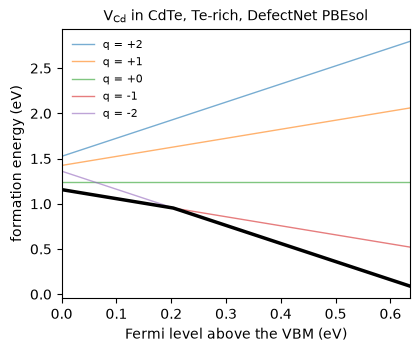

In [8]:
for e, q1, q2 in dn.transition_levels(ef0, GAP):
    print(f"level ({q1:+d}/{q2:+d}) at {e:.3f} eV above the VBM")

x, env = dn.fermi_grid(ef0, GAP)
fig, ax = plt.subplots(figsize=(4.5, 3.5))
for q in ef0:
    ax.plot(x, ef0[q] + q * x, lw=1, alpha=0.6, label=f"q = {q:+d}")
ax.plot(x, env, "k", lw=2.5)
ax.set_xlim(0, GAP)
ax.set_xlabel("Fermi level above the VBM (eV)")
ax.set_ylabel("formation energy (eV)")
ax.set_title(r"V$_\mathrm{Cd}$ in CdTe, Te-rich, DefectNet PBEsol", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.show()

## 6. Vacancy migration barrier

The vacancy moves when a neighbouring Cd jumps into it. `dn.vacancy_hop` relaxes the initial state (vacancy on
site 0) and the final state (the nearest Cd moved onto site 0), interpolates seven images between them with IDPP,
and relaxes the band with a climbing image (CI-NEB). The migration barrier is

$$E_m = \max_k E_k - E_0 .$$

This takes about ten minutes on one GPU.

V_Cd q = -2: hop 4.59 A, barrier 1.045 eV, converged True


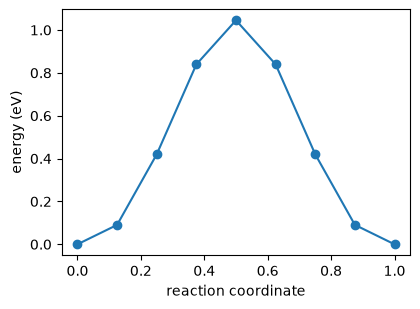

In [9]:
r = dn.vacancy_hop(host, site=0, calc=calc, q=-2)
print(f"V_Cd q = -2: hop {r['hop_length']:.2f} A, barrier {r['Em_fwd']:.3f} eV, converged {r['converged']}")

E = np.array(r["E"]) - r["E"][0]
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.plot(np.linspace(0, 1, len(E)), E, "o-")
ax.set_xlabel("reaction coordinate")
ax.set_ylabel("energy (eV)")
plt.show()

## 7. Fine-tune on your own DFT data

### Frames

Every ionic step of a DFT run becomes one training frame with its energy, forces and stress, the head of
its level of theory and its total charge. `defectnet.dataset.frames` does this for any file `ase.io.read` reads
(VASP `vasprun.xml` or `OUTCAR`, Quantum ESPRESSO output, and others). The command line equivalent is
`defectnet-data --functional PBEsol --charge 0 -o train.xyz vasprun.xml`.

The example data in `data/` are real CdTe calculations: one PBEsol `vasprun.xml` of the 2-atom cell, plus frames
already converted from an 8-atom PBEsol relaxation and an 8-atom HSE06(PBEsol) relaxation. Use one head per level
of theory, and for your own system include the pristine cells and elemental references along with the defects,
because formation energies are differences between them.

In [10]:
from ase.io import read, write
from defectnet.dataset import frames

train = frames("data/CdTe_PBEsol_2atoms_vasprun.xml", "PBEsol", charge=0)
train += read("data/CdTe_8atoms_frames.xyz", index=":")
write("train.xyz", train, format="extxyz")

head_name = {v: k for k, v in dn.FUNCTIONALS.items()}
for a in train:
    print(f"{len(a):3d} atoms  {head_name[a.info['fidelity_idx']]:14s} q = {a.info['total_charge']:+.0f}  "
          f"E = {a.get_potential_energy() / len(a):.4f} eV/atom")

  2 atoms  PBEsol         q = +0  E = -2.7415 eV/atom
  8 atoms  PBEsol         q = +0  E = -2.7299 eV/atom
  8 atoms  PBEsol         q = +0  E = -2.7443 eV/atom
  8 atoms  PBEsol         q = +0  E = -2.7449 eV/atom
  8 atoms  HSE06(PBEsol)  q = +0  E = -3.2566 eV/atom
  8 atoms  HSE06(PBEsol)  q = +0  E = -3.2575 eV/atom
  8 atoms  HSE06(PBEsol)  q = +0  E = -3.2584 eV/atom


### Errors before fine-tuning

For each frame, the energy error per atom is

$$\Delta e = \frac{E^\mathrm{DN} - E^\mathrm{DFT}}{N}.$$

The atoms in these small zinc-blende cells sit on symmetric sites, so the DFT and DefectNet forces are both zero and
only the energy is compared. In a defect cell compare the forces too.

In [11]:
def errors(model):
    calcs = {h: dn.load(model, functional=h) for h in {a.info["fidelity_idx"] for a in train}}
    out = []
    for a in train:
        b = dn.charged(a, a.info["total_charge"])
        b.calc = calcs[a.info["fidelity_idx"]]
        out.append((b.get_potential_energy() - a.get_potential_energy()) / len(a))
    out = np.array(out)
    print(f"{model}: energy MAE {1000 * np.abs(out).mean():.1f} meV/atom")
    return out

before = errors(MODEL)

DefectNet-v1.0.pt: energy MAE 6.1 meV/atom


### Training

`defectnet-train` (TACE's `tace-train` with the periodic QEq electrostatics of DefectNet registered first) minimises a weighted sum of squared errors over the frames,

$$\mathcal L = w_e\,\overline{(\Delta e)^2} + w_F\,\overline{|\Delta \mathbf F|^2} + w_\sigma\,\overline{|\Delta \sigma|^2}
+ w_E\,\overline{(\Delta E)^2},$$

with the weights DefectNet was trained with ($w_e = 50$, $w_F = 5$, $w_\sigma = 0.5$, $w_E = 0.01$), starting
from the DefectNet weights. The template `finetune/finetune.yaml` sets everything; the command line below only
shortens the run to 100 steps for this small example and keeps two of the seven frames for validation. For a real
data set keep the template's 2,000 steps (or more) and its learning rate of $10^{-5}$.

A checkpoint with its optimizer state is about 4.4 GB and is built in memory, so train on a machine with at least
16 GB of RAM.

In [12]:
%%bash
cp ../finetune/finetune.yaml .
defectnet-train -cn finetune.yaml finetune_from_model=DefectNet-v1.0.pt dataset.train_file=train.xyz \
  dataset.valid_ratio=0.3 trainer.max_steps=100 scheduler.first_cycle_steps=100 scheduler.warmup_steps=10 \
  trainer.val_check_interval=1.0 callbacks.checkpoint_step.every_n_train_steps=100 \
  callbacks.checkpoint_epoch.every_n_epochs=1000 \
  dataset.train_dataloader.num_workers=0 dataset.valid_dataloader.num_workers=0 > finetune.log 2>&1
echo "exit code $?"; ls checkpoints

exit code 0


last.ckpt
TACE-full-19-100.ckpt


The checkpoint holds the optimizer state as well. Strip it to a weights file, which loads like the original model.

In [13]:
%%bash
tace-export-train -m checkpoints/last.ckpt -o my_model.pt --dtype float32 > export.log 2>&1
echo "exit code $?"; ls -lh my_model.pt | awk '{print $5, $9}'

exit code 0


850M my_model.pt


## 8. Use the fine-tuned model

The same calls work with the new file. With seven frames and 100 steps this is only a demonstration of the
procedure; most of these frames were also used for training, so the drop in error below is not a validation.
Judge a real fine-tune on frames it has not seen, and on the defect properties you care about.

In [14]:
after = errors("my_model.pt")

calc_ft = dn.load("my_model.pt", functional="PBEsol")
a = dn.charged(cell, 0)
a.calc = calc_ft
print(f"216-atom CdTe with the fine-tuned PBEsol head: {a.get_potential_energy() / len(a):.4f} eV/atom")

my_model.pt: energy MAE 1.3 meV/atom


216-atom CdTe with the fine-tuned PBEsol head: -2.7451 eV/atom


## Notes

- `examples/02_formation_energy.py` and `examples/03_vacancy_neb.py` are the scripts behind sections 5 and 6.
- The PBEsol head is the accurate one for defect energetics. The PBE and hybrid heads give formation energies off by
  about 1 eV (root-mean-square) even on geometries relaxed with the PBEsol head; use them for single points on
  PBEsol geometries at most.
- In some charge states the DefectNet minimum can differ from the DFT one. Check structures that matter with a DFT
  relaxation started from the DefectNet geometry.